# ЛАБОРАТОРНА РОБОТА № 4

## Візуальний аналіз даних та часові ряди — аналіз у двох середовищах

**Курс:** СК26 «Інтелектуальний аналіз та візуалізація даних»
**Кафедра систем штучного інтелекту, Національний університет «Львівська політехніка»**
**Оцінювання:** 4 бали

---

## Визначення варіанта

Заповніть три поля в клітинці нижче й виконайте обидві службові клітинки —
номер варіанта, ринок і товар визначаться автоматично.

In [1]:
# ── Заповніть три поля ──────────────────────────────────────────
SURNAME_NAME = 'Кутельмах Євген'      # прізвище та ім'я
GROUP        = 'ШІ-34'      # шифр групи, наприклад СШІ-31
NUMBER       = 8       # ваш номер за списком групи (1–30)

assert SURNAME_NAME.strip(), 'Впишіть прізвище та ім\'я'
assert GROUP.strip(),        'Впишіть групу'
assert isinstance(NUMBER, int) and 1 <= NUMBER <= 30, 'Номер має бути цілим від 1 до 30'
print('Дані прийнято:', SURNAME_NAME, '|', GROUP, '| номер', NUMBER)

Дані прийнято: Кутельмах Євген | ШІ-34 | номер 8


In [2]:
# ── Службова клітинка: визначення варіанта. Змінювати не потрібно ──
import json

VARIANTS = json.load(open('lr4_variants_student.json', encoding='utf-8'))
V = VARIANTS[NUMBER - 1]

MARKET, GOOD, GOOD_UA = V['ринок'], V['товар'], V['товар_укр']

print('=' * 72)
print(f'ВАРІАНТ {V["варіант"]}   ·   {SURNAME_NAME}   ·   {GROUP}')
print('=' * 72)
print()
print(f'   Ринок:  {MARKET}')
print(f'   Товар:  {GOOD_UA}   (у наборі даних: {GOOD})')
print()
print('Далі в роботі користуйтеся змінними MARKET і GOOD —')
print('тоді весь код автоматично працюватиме саме з вашим рядом.')
print()
print('Період: 03.2014 – 12.2017 · очікувана довжина ряду: 46 місяців')
print('Фолдів ретроспективної перевірки: 7 · горизонт: 3 місяці · ARIMA(1, 1, 1)')

ВАРІАНТ 8   ·   Кутельмах Євген   ·   ШІ-34

   Ринок:  Odesa
   Товар:  сметана   (у наборі даних: Sour cream - Retail)

Далі в роботі користуйтеся змінними MARKET і GOOD —
тоді весь код автоматично працюватиме саме з вашим рядом.

Період: 03.2014 – 12.2017 · очікувана довжина ряду: 46 місяців
Фолдів ретроспективної перевірки: 7 · горизонт: 3 місяці · ARIMA(1, 1, 1)


> ⚠️ Якщо ці дві клітинки не виконано, усі подальші завдання не мають сенсу:
> перевіряти роботу будуть **за вашим варіантом**, а не за тим рядом, який ви оберете самі.

| | |
|---|---|
| **Дата здачі** | |
| **Підпис** | |

---
## Мета роботи

Виконати повний цикл аналізу одного часового ряду **у двох середовищах** — у Python та в Orange —
і пояснити, чому однаково названі метрики в них дають різні числа.

## Вихідні дані

| Файл | Зміст |
|---|---|
| `ціни_україна_2014_2017.csv` | Роздрібні ціни на 25 товарів по 28 ринках України, щомісяця, 03.2014 – 12.2017 |
| `lr4_variants_student.json` | Розподіл варіантів (зчитується автоматично) |
| `ЛР4_помилковий_аналіз.ipynb` | Звіт колеги, який треба відрецензувати (завдання 8) |

Це той самий набір, з яким ми працювали на лекції 4. **Національне середнє в завданнях не використовується** —
ваш ряд це конкретний обласний ринок.

## Що здавати

1. **`ЛР4_Прізвище_Варіант.ipynb`** — цей зошит із вашим кодом, графіками та письмовими висновками.
2. **`ряд_для_orange.csv`** — експортований ряд (завдання 9).
3. **`потік_orange.ows`** — збережений потік Orange.
4. **Знімки екрана** з Orange для завдань 10–13 — вставте їх у зошит або додайте окремими файлами.

## Правила

* **Код пишете самостійно** — у цьому зошиті навмисно немає заготовок.
* **Користуватися штучним інтелектом дозволено**, але ви зобов'язані заповнити декларацію в кінці зошита.
* **Кожне число має супроводжуватися висновком словами.** Робота, у якій є графіки й таблиці,
  але немає письмових відповідей на поставлені питання, оцінюється як невиконана.
* Усі обчислення мають бути **відтворюваними**: зошит має виконуватися від початку до кінця
  командою *Restart & Run All* без помилок.

---
# ЧАСТИНА 1. Аналіз засобами Python

*Виконується аудиторно.*

## Завдання 1. Підготовка ряду

Витягніть із набору ряд свого варіанта — скористайтеся змінними `MARKET` і `GOOD`,
які визначилися у службовій клітинці, — і приведіть його до **повної місячної сітки**
з березня 2014 по грудень 2017.

**У звіті наведіть:**
1. скільки місяців у сітці та скільки з них мають вимір;
2. у якому саме місяці пропуск;
3. **чому** цей пропуск виник — і чи він у вашому ряді один.

> 💡 **Підказка.** Пропуск є в усіх без винятку рядах набору. Якщо ви знайшли більше одного — перевірте, чи правильно побудована сітка.

In [3]:
# Завдання 1. Підготовка ряду
import pandas as pd
import numpy as np

df = pd.read_csv('ціни_україна_2014_2017.csv')
df_filtered = df[(df['ринок'] == MARKET) & (df['товар'] == GOOD)].copy()
df_filtered['дата'] = pd.to_datetime(
    df_filtered['рік'].astype(str) + '-' + df_filtered['місяць'].astype(str) + '-01'
)
df_filtered = df_filtered.set_index('дата').sort_index()
df_filtered = df_filtered.drop(columns=['місяць', 'рік'])

df_full_grid = df_filtered.resample('MS').asfreq()

df_full_grid

,ринок,товар,одиниця,валюта,ціна
дата,,,,,
2014-03-01,Odesa,Sour cream - Retail,L,UAH,20.8700
2014-04-01,Odesa,Sour cream - Retail,L,UAH,20.9133
2014-05-01,Odesa,Sour cream - Retail,L,UAH,21.0667
2014-06-01,Odesa,Sour cream - Retail,L,UAH,21.3200
2014-07-01,Odesa,Sour cream - Retail,L,UAH,21.4200
2014-08-01,Odesa,Sour cream - Retail,L,UAH,21.4200
2014-09-01,Odesa,Sour cream - Retail,L,UAH,21.4200
2014-10-01,Odesa,Sour cream - Retail,L,UAH,22.4867
2014-11-01,Odesa,Sour cream - Retail,L,UAH,22.8000


**Висновок до завдання 1:**

*(напишіть тут)*
У датасеті 46 записів (місяців), 1 з них, а саме травень 2017 не містить значення. Це єдиний пропуск, який виник, оскільки запис відстуній в csv файлі

## Завдання 2. Заповнення пропуску

Заповніть пропуск. Порівняйте **щонайменше три** способи: перенесення останнього значення,
лінійну інтерполяцію та ще один на ваш вибір.

**У звіті наведіть:**
1. значення, яке дає кожен спосіб;
2. який спосіб ви обрали і **чому саме його**;
3. за якої умови заповнювати пропуск було б **неприпустимо** — наведіть приклад із цього ж набору даних.

> 💡 **Підказка.** Третій пункт стосується не вашого ряду, а принципу. Згадайте, які області зникають із набору у 2014 році.

In [4]:
# Завдання 2. Заповнення пропуску
data = {
    '2017-07-01': 44.8267,
    '2017-08-01': np.nan,
    '2017-09-01': 44.8000
}
zap_df = pd.DataFrame(list(data.items()), columns=['дата', 'ціна'])
zap_df['дата'] = pd.to_datetime(zap_df['дата'])
zap_df = zap_df.set_index('дата')

zap_df['ціна_ffill'] = zap_df['ціна'].ffill()
zap_df['ціна_linear'] = zap_df['ціна'].interpolate(method='linear')
zap_df['ціна_bfill'] = zap_df['ціна'].bfill()

df_full_grid['ціна'] = df_full_grid['ціна'].interpolate(method='linear')

zap_df

,ціна,ціна_ffill,ціна_linear,ціна_bfill
дата,,,,
2017-07-01,44.8267,44.8267,44.82670,44.8267
2017-08-01,NaN,44.8267,44.81335,44.8000
2017-09-01,44.8000,44.8000,44.80000,44.8000


**Висновок до завдання 2:**

*(напишіть тут)*
forward fill дає значення 44.8267, linear interpolate - 44.81335, bfill - 44.8000
Для випадку сметани краще обрати лінійну інтерполяцію, адже цей метод дасть більш ймовірне значення
Якщо пропущено відносно довгий послідовний період, то отримані результати будуть дуже спотворені. За 2016 рік ціни змінились з 29.6467 до 39.1867, проте більшість року вони були в районі 31-32 гривень, ціни підскочили лише в останні 3 місяці.

## Завдання 3. Візуальна розвідка

Побудуйте **не менше трьох** графіків свого ряду, які відповідають на різні питання.

**У звіті наведіть:**
1. для кожного графіка — яке питання він ставить і **чому обрано саме таку геометрію та шкалу**;
2. одну знахідку, якої ви не очікували до побудови графіків.

> 💡 **Підказка.** Графік без пояснення вибору форми не зараховується. Нагадування з лекції: геометрія — це твердження про дані.

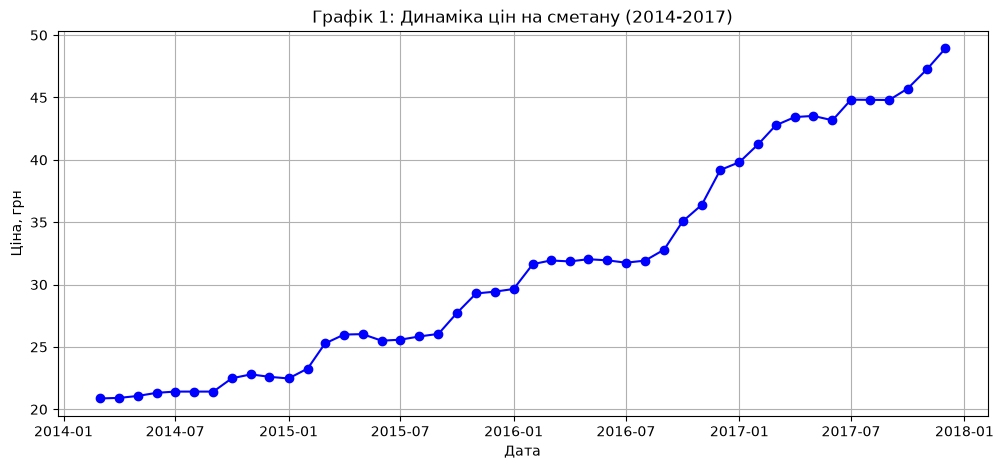

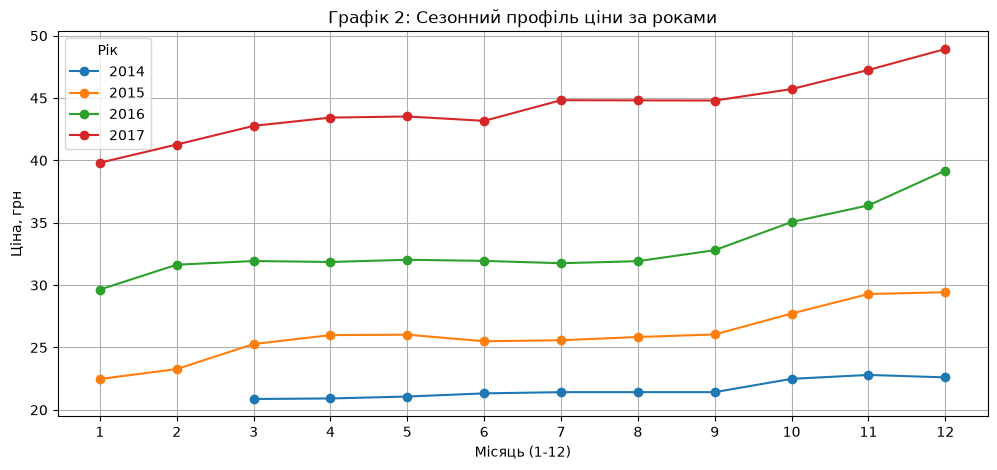

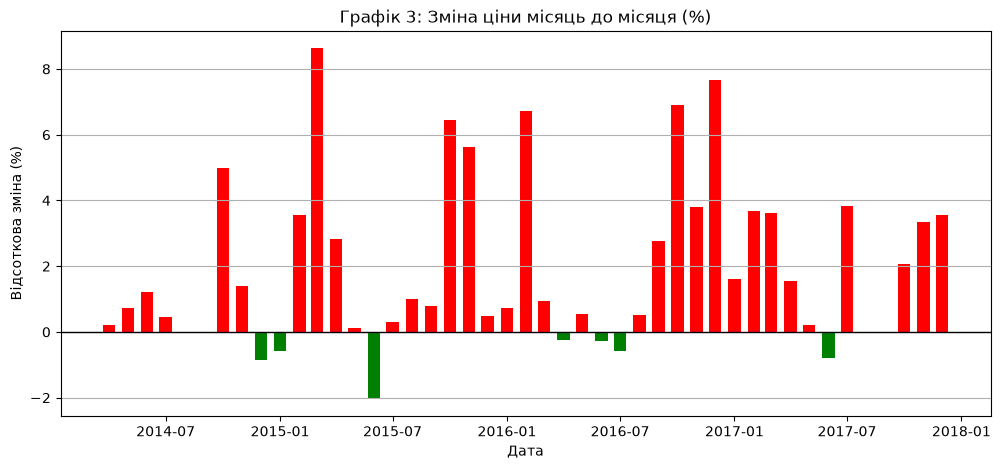

In [5]:
# Завдання 3. Візуальна розвідка
import matplotlib.pyplot as plt

plt.figure(figsize=(12, 5))
plt.plot(df_full_grid.index, df_full_grid['ціна'], marker='o', linestyle='-', color='b')

plt.title('Графік 1: Динаміка цін на сметану (2014-2017)')
plt.ylabel('Ціна, грн')
plt.xlabel('Дата')
plt.grid(True)
plt.show()

df_full_grid['рік'] = df_full_grid.index.year
df_full_grid['місяць'] = df_full_grid.index.month

pivot = df_full_grid.pivot(index='місяць', columns='рік', values='ціна')

plt.figure(figsize=(12, 5))
for year in pivot.columns:
    plt.plot(pivot.index, pivot[year], marker='o', label=str(year))

plt.title('Графік 2: Сезонний профіль ціни за роками')
plt.ylabel('Ціна, грн')
plt.xlabel('Місяць (1-12)')
plt.xticks(range(1, 13))
plt.legend(title='Рік')
plt.grid(True)
plt.show()

df_full_grid['зміна_%'] = df_full_grid['ціна'].pct_change() * 100

plt.figure(figsize=(12, 5))
colors = ['red' if x > 0 else 'green' for x in df_full_grid['зміна_%']]

plt.bar(df_full_grid.index, df_full_grid['зміна_%'], width=20, color=colors)

plt.title('Графік 3: Зміна ціни місяць до місяця (%)')
plt.ylabel('Відсоткова зміна (%)')
plt.xlabel('Дата')
plt.axhline(0, color='black', linewidth=1)
plt.grid(True, axis='y')
plt.show()

df_full_grid = df_full_grid.drop(columns=['рік', 'місяць', 'зміна_%'])

**Висновок до завдання 3:**

*(напишіть тут)*
1 - Яким був загальний тренд вартості сметани; обрано неперервну лінію з точками, оскільки дані неперервні та маркери чітко показують значення по місяцях
2 - Чи є сезонність в ціноутворені сметани; обрано декілька кривих на одній системі координат, тому що нам важливо порівнювати певні періоди, а не повні інтервали
3 - Наскільки різкими бувають зміни цін, коли відбулись найбільші стрибки; обрано стовпчикову діаграму з кольоровим кодуванням в відсотковій шкалі, щоб дані були більш читабельними

Знахідка - третій графік показує, що найбільші стрибки відбуваються у переході з вересня на жовтень, кожен рік ціни зростають хоча б на 2 відсотки.

## Завдання 4. Розкладання на складові

Розкладіть ряд на тренд, сезонну складову та залишок методом STL із періодом 12.

**У звіті наведіть:**
1. чотирипанельний графік розкладання;
2. числові значення сили сезонності $F_S$ та сили тренду $F_T$;
3. **висновок: чи є у вашому ряді сезонність**, із посиланням на порогове значення.

> 💡 **Підказка.** STL поверне сезонну складову завжди. Ваше завдання — вирішити, чи вона означає щось, а не чи вона є.

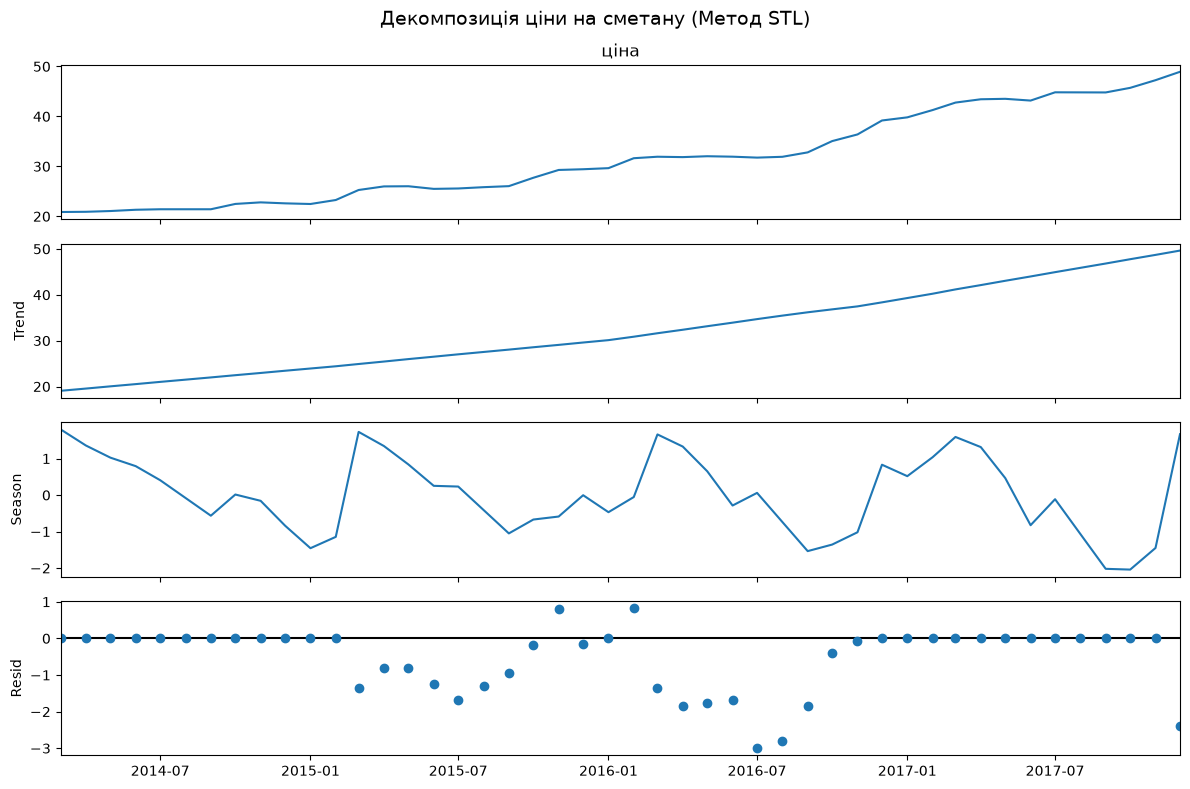

Сила тренду (F_T): 0.9901
Сила сезонності (F_S): 0.5068


In [6]:
# Завдання 4. Розкладання на складові
from statsmodels.tsa.seasonal import STL

stl = STL(df_full_grid['ціна'], period=12, robust=True)
res = stl.fit()

fig = res.plot()
fig.set_size_inches(12, 8)
fig.suptitle('Декомпозиція ціни на сметану (Метод STL)', fontsize=14)
plt.tight_layout()
plt.show()

T = res.trend
S = res.seasonal
R = res.resid

var_R = np.var(R)
var_TR = np.var(T + R)
var_SR = np.var(S + R)

F_t = max(0, 1 - var_R / var_TR)
F_s = max(0, 1 - var_R / var_SR)

print(f"Сила тренду (F_T): {F_t:.4f}")
print(f"Сила сезонності (F_S): {F_s:.4f}")

**Висновок до завдання 4:**

*(напишіть тут)*
Даний ряд має сезонність, адже графік показує циклічність, сила сезонності також це покакзує 

## Завдання 5. Стаціонарність

Побудуйте ACF і PACF вихідного ряду та його першої різниці. Застосуйте тести ADF і KPSS до обох.

**У звіті наведіть:**
1. графіки ACF і PACF до та після диференціювання;
2. таблицю з $p$-значеннями обох тестів для обох рядів;
3. висновок про стаціонарність **із зазначенням, узгоджуються тести між собою чи ні**;
4. якщо не узгоджуються — ваше пояснення, чому.

> 💡 **Підказка.** Нульові гіпотези ADF і KPSS протилежні. Перш ніж писати висновок, перевірте, що ви не переплутали напрямок.

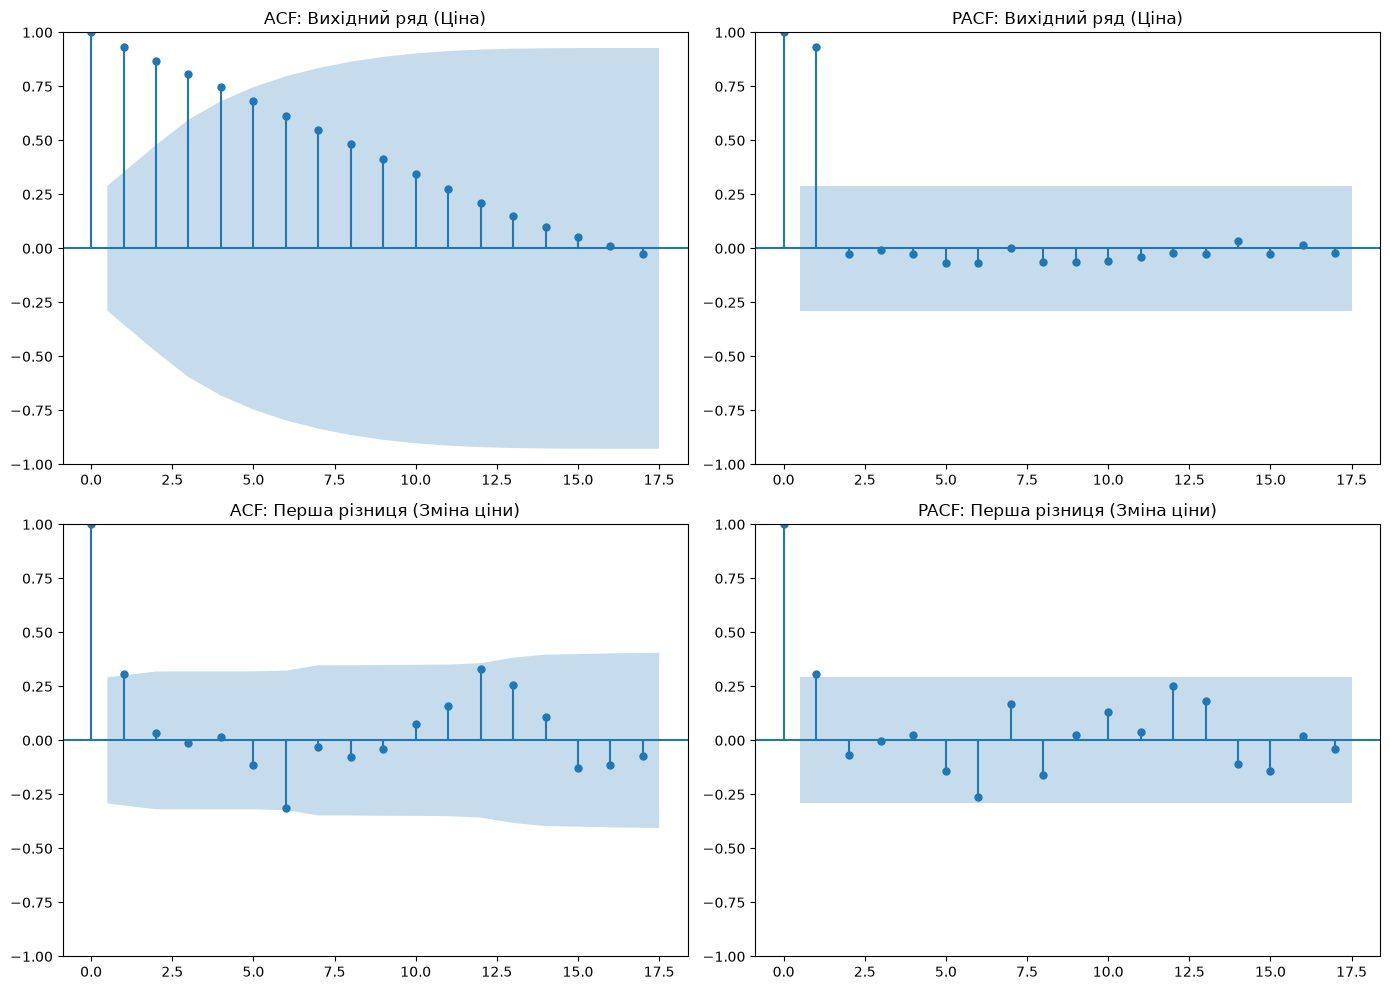

--- Тести для: Вихідний ряд (Ціна) ---
ADF p-value:  0.9951
KPSS p-value: 0.0100

--- Тести для: Перша різниця (Зміна ціни) ---
ADF p-value:  0.0002
KPSS p-value: 0.0954



In [7]:
# Завдання 5. Стаціонарність
from statsmodels.graphics.tsaplots import plot_acf, plot_pacf
from statsmodels.tsa.stattools import adfuller, kpss
import warnings
warnings.filterwarnings("ignore")

y_diff = df_full_grid['ціна'].diff().dropna()

fig, axes = plt.subplots(2, 2, figsize=(14, 10))

plot_acf(df_full_grid['ціна'], ax=axes[0, 0], title='ACF: Вихідний ряд (Ціна)')
plot_pacf(df_full_grid['ціна'], ax=axes[0, 1], title='PACF: Вихідний ряд (Ціна)')

plot_acf(y_diff, ax=axes[1, 0], title='ACF: Перша різниця (Зміна ціни)')
plot_pacf(y_diff, ax=axes[1, 1], title='PACF: Перша різниця (Зміна ціни)')

plt.tight_layout()
plt.show()

def run_stationarity_tests(series, name):
    adf_res = adfuller(series)
    adf_p = adf_res[1]
    
    kpss_res = kpss(series, regression='c', nlags="auto")
    kpss_p = kpss_res[1]
    
    print(f"--- Тести для: {name} ---")
    print(f"ADF p-value:  {adf_p:.4f}")
    print(f"KPSS p-value: {kpss_p:.4f}\n")

run_stationarity_tests(df_full_grid['ціна'], "Вихідний ряд (Ціна)")
run_stationarity_tests(y_diff, "Перша різниця (Зміна ціни)")

**Висновок до завдання 5:**

*(напишіть тут)*
Тести узгоджуються, вихідні дані - нестаціонарні, різниця - стаціонарна, тому що нульові гіпотези тестів протилежні, adf стверджує, що дані стаціонарні якщо p > 0.05, kpss стверджує протилежне 

## Завдання 6. Базисні прогнози та ретроспективна перевірка

Побудуйте **чотири** базисні прогнози: наївний, сезонний наївний, середнє та дрейф.
Оцініть їх **ретроспективною перевіркою з рухомим початком**: **7 фолдів по 3 кроки**,
навчальна частина розширюється.

**У звіті наведіть:**
1. таблицю MAE, RMSE і MAPE для всіх чотирьох базисів;
2. який базис виявився найкращим і **чому саме він** — поясніть через властивості вашого ряду;
3. для порівняння: ту саму оцінку, зроблену звичайним випадковим поділом 75/25, і **у скільки разів** вона відрізняється.

> 💡 **Підказка.** Кількість фолдів і кроків задана жорстко — у Частині 2 вона має збігтися з налаштуваннями Orange.

In [8]:
# Завдання 6. Базисні прогнози та ретроспективна перевірка
from sklearn.metrics import mean_absolute_error, mean_squared_error

y = df_full_grid['ціна'].values
n = len(y)

folds = 7
horizon = 3
test_size_total = folds * horizon

def mape(y_true, y_pred):
    return np.mean(np.abs((y_true - y_pred) / y_true)) * 100

errors_cv = {
    'Naive': {'mae': [], 'rmse': [], 'mape': []},
    'SNaive': {'mae': [], 'rmse': [], 'mape': []},
    'Mean': {'mae': [], 'rmse': [], 'mape': []},
    'Drift': {'mae': [], 'rmse': [], 'mape': []}
}

for i in range(folds):
    train_end = n - test_size_total + (i * horizon)
    
    train = y[:train_end]
    test = y[train_end : train_end + horizon]
    
    pred_naive = np.full(horizon, train[-1])
    
    pred_snaive = train[-12 : -12 + horizon]
    
    pred_mean = np.full(horizon, train.mean())
    
    drift_slope = (train[-1] - train[0]) / (len(train) - 1)
    pred_drift = train[-1] + np.arange(1, horizon + 1) * drift_slope
    
    preds = {'Naive': pred_naive, 'SNaive': pred_snaive, 'Mean': pred_mean, 'Drift': pred_drift}
    
    for model_name, p in preds.items():
        errors_cv[model_name]['mae'].append(mean_absolute_error(test, p))
        errors_cv[model_name]['rmse'].append(np.sqrt(mean_squared_error(test, p)))
        errors_cv[model_name]['mape'].append(mape(test, p))

print("=== Оцінка Rolling Origin (7 фолдів по 3 кроки) ===")
for m in errors_cv.keys():
    print(f"{m:8} | MAE: {np.mean(errors_cv[m]['mae']):.2f} | RMSE: {np.mean(errors_cv[m]['rmse']):.2f} | MAPE: {np.mean(errors_cv[m]['mape']):.2f}%")

train_idx = int(n * 0.75)
train_75 = y[:train_idx]
test_25 = y[train_idx:]
h_75 = len(test_25)

pred_drift_75 = train_75[-1] + np.arange(1, h_75 + 1) * ((train_75[-1] - train_75[0]) / (len(train_75) - 1))
mae_drift_75 = mean_absolute_error(test_25, pred_drift_75)
mae_drift_cv = np.mean(errors_cv['Drift']['mae'])

print(f"\n=== Порівняння найкращої моделі (Drift) ===")
print(f"MAE (CV 7 фолдів): {mae_drift_cv:.2f}")
print(f"MAE (75/25 сплит): {mae_drift_75:.2f}")
print(f"Різниця у {mae_drift_75 / mae_drift_cv:.1f} разів")

=== Оцінка Rolling Origin (7 фолдів по 3 кроки) ===
Naive    | MAE: 1.62 | RMSE: 1.79 | MAPE: 3.92%
SNaive   | MAE: 9.32 | RMSE: 9.34 | MAPE: 23.14%
Mean     | MAE: 12.20 | RMSE: 12.24 | MAPE: 29.90%
Drift    | MAE: 1.19 | RMSE: 1.37 | MAPE: 3.06%

=== Порівняння найкращої моделі (Drift) ===
MAE (CV 7 фолдів): 1.19
MAE (75/25 сплит): 1.40
Різниця у 1.2 разів


**Висновок до завдання 6:**

*(напишіть тут)*
Найкращий прогноз - drift, має найнижчі показники у всіх метриках. Дані стаціонарні та ціна має сильний тренд, тому дрейф (єдиний прогноз, який враховує кут нахилу) дає найкращий результат.

## Завдання 7. Модель ARIMA

Побудуйте модель ARIMA і оцініть її **на тих самих 7 фолдах по 3 кроки**.

Обов'язково використайте порядок **(1, 1, 1)** — саме його ви відтворюватимете в Orange.
Додатково визначте, який порядок $(p, d, q)$ ви обрали б **за виглядом ACF і PACF** із завдання 5.

**У звіті наведіть:**
1. MAE, RMSE і MAPE моделі ARIMA(1,1,1) на рухомому початку;
2. обґрунтування порядку, який ви обрали б самостійно, з посиланням на конкретні лаги;
3. **порівняння з найкращим базисом із завдання 6** — і прямий висновок, чи має ця модель право на існування;
4. графік залишків моделі та висновок, чи лишилася в них структура.

> 💡 **Підказка.** Якщо ARIMA програла базису — це законний результат, а не помилка. Напишіть про це прямо.

=== Оцінка ARIMA(1,1,1) на рухомому початку ===
MAE:  1.24
RMSE: 1.37
MAPE: 3.11%



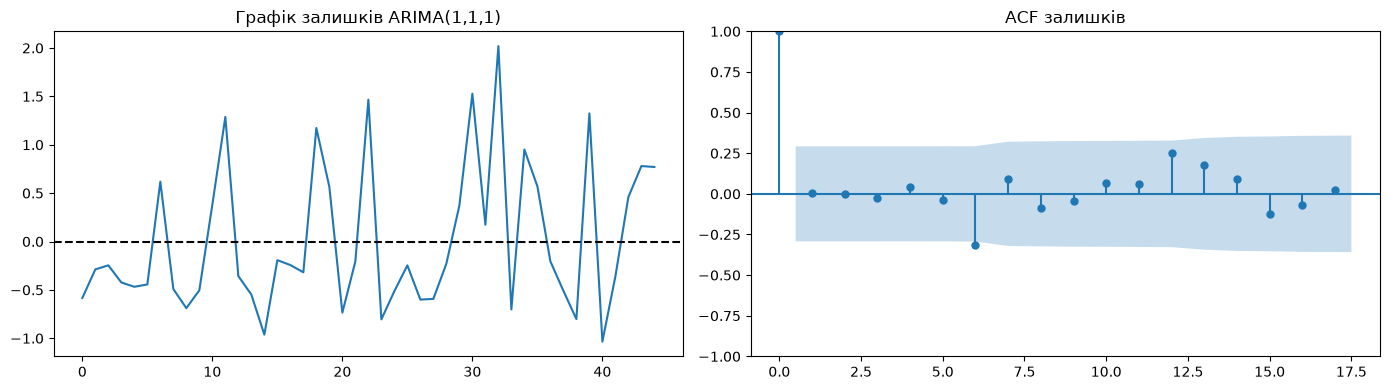

In [9]:
# Завдання 7. Модель ARIMA
from statsmodels.tsa.arima.model import ARIMA

errors_arima = {'mae': [], 'rmse': [], 'mape': []}

for i in range(folds):
    train_end = n - test_size_total + (i * horizon)
    train = y[:train_end]
    test = y[train_end : train_end + horizon]
    
    model = ARIMA(train, order=(1, 1, 1), trend='t')
    fitted = model.fit()
    
    pred = fitted.forecast(steps=horizon)
    
    errors_arima['mae'].append(mean_absolute_error(test, pred))
    errors_arima['rmse'].append(np.sqrt(mean_squared_error(test, pred)))
    errors_arima['mape'].append(mape(test, pred))

mae_arima = np.mean(errors_arima['mae'])
rmse_arima = np.mean(errors_arima['rmse'])
mape_arima = np.mean(errors_arima['mape'])

print("=== Оцінка ARIMA(1,1,1) на рухомому початку ===")
print(f"MAE:  {mae_arima:.2f}")
print(f"RMSE: {rmse_arima:.2f}")
print(f"MAPE: {mape_arima:.2f}%\n")

final_model = ARIMA(y, order=(1, 1, 1), trend='t')
final_fitted = final_model.fit()
residuals = final_fitted.resid[1:]

fig, axes = plt.subplots(1, 2, figsize=(14, 4))
axes[0].plot(residuals)
axes[0].set_title('Графік залишків ARIMA(1,1,1)')
axes[0].axhline(0, color='black', linestyle='--')

plot_acf(residuals, ax=axes[1], title='ACF залишків')

plt.tight_layout()
plt.show()


**Висновок до завдання 7:**

*(напишіть тут)*
Drift           | MAE: 1.19 | RMSE: 1.37 | MAPE: 3.06%
ARIMA(1,1,1)    | MAE: 1.24 | RMSE: 1.37 | MAPE: 3.11%

Я б самостійно обрав ARIMA(0,1,0), бо після першої різниці значущих лагів не лишилося, і оскільки звичайний базис надав кращі результати, використовувати складнішу модель просто немає сенсу.

У залишках лишилася структура. На графіку ACF виходить за межі довірчого інтервалу 6-й лаг — це означає, що в даних є прихована піврічна циклічність, яку наша модель не змогла пояснити

## Завдання 8. Точка зміни режиму

Знайдіть у своєму ряді точку, після якої змінюється **рівень** ряду.
Скористайтеся скануванням: для кожної кандидатної дати порівняйте середні до і після
та оберіть дату з найбільшою t-статистикою.

**У звіті наведіть:**
1. графік ряду з позначеною знайденою датою;
2. дату, значення t-статистики, середні рівні до і після;
3. **чи є ця точка значущою** — і якщо ні, так і напишіть;
4. чим знайдена точка відрізняється від звичайного сезонного сплеску у вашому ряді.

> 💡 **Підказка.** Не плутайте зсув рівня з сезонним піком. Якщо «аномалії» повторюються щороку в ті самі місяці — це сезон.

Знайдена точка розбиття: 2016-12
Максимальна t-статистика: 15.17
Середнє ДО: 26.84 грн
Середнє ПІСЛЯ: 43.81 грн


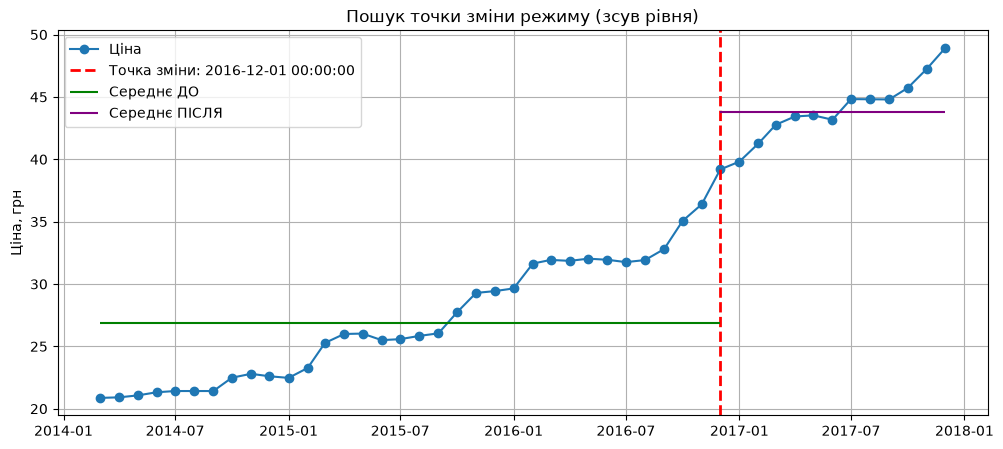

In [10]:
# Завдання 8. Точка зміни режиму
from scipy.stats import ttest_ind

t_stats = np.zeros(n)

for i in range(3, n - 3):
    group1 = y[:i]
    group2 = y[i:]
    t_stat, p_val = ttest_ind(group1, group2, equal_var=False)
    t_stats[i] = np.abs(t_stat)

best_idx = np.argmax(t_stats)
best_date = df_full_grid.index[best_idx]
max_t = t_stats[best_idx]
mean_before = np.mean(y[:best_idx])
mean_after = np.mean(y[best_idx:])

print(f"Знайдена точка розбиття: {best_date.strftime('%Y-%m') if hasattr(best_date, 'strftime') else best_date}")
print(f"Максимальна t-статистика: {max_t:.2f}")
print(f"Середнє ДО: {mean_before:.2f} грн")
print(f"Середнє ПІСЛЯ: {mean_after:.2f} грн")

plt.figure(figsize=(12, 5))
plt.plot(df_full_grid.index, y, marker='o', label='Ціна')
plt.axvline(x=best_date, color='red', linestyle='--', linewidth=2, label=f'Точка зміни: {best_date}')
plt.hlines(mean_before, xmin=df_full_grid.index[0], xmax=best_date, colors='green', linestyles='solid', label='Середнє ДО')
plt.hlines(mean_after, xmin=best_date, xmax=df_full_grid.index[-1], colors='purple', linestyles='solid', label='Середнє ПІСЛЯ')

plt.title('Пошук точки зміни режиму (зсув рівня)')
plt.ylabel('Ціна, грн')
plt.legend()
plt.grid(True)
plt.show()

**Висновок до завдання 8:**

*(напишіть тут)*

Дата - 2016-12, t-статистика - 15.17, середнє ДО: 26.84 грн, середнє ПІСЛЯ: 43.81 грн

Точка є значущою, адже максимальне значення t, значно переважає 2

Під час сезонного сплеску ціна після підвищення повертається назад - знайдена точка не була б значущою

## Завдання 9. Рецензія на чужий аналіз

Відкрийте `ЛР4_помилковий_аналіз.ipynb`. Це звіт, зроблений на іншому ряді з того самого набору.
Він виконується без помилок і виглядає переконливо, але містить **методологічні помилки**.

**У звіті наведіть:**
1. перелік знайдених помилок — для кожної вкажіть номер клітинки, суть помилки й **чим вона небезпечна**;
2. для трьох найсерйозніших — як саме їх виправити.

> 💡 **Підказка.** Помилок щонайменше вісім. Шукайте не синтаксис, а порушення принципів роботи з часовими рядами.

In [ ]:
# Завдання 9. Рецензія на чужий аналіз
# Створити повну місячну сітку, а не пропускати Nan
df = pd.read_csv('ціни_україна_2014_2017.csv')
df_filtered9 = df[(df['ринок'] == MARKET) & (df['товар'] == GOOD)].copy()
df_filtered9['дата'] = pd.to_datetime(
    df_filtered9['рік'].astype(str) + '-' + df_filtered9['місяць'].astype(str) + '-01'
)
df_filtered9 = df_filtered9.set_index('дата').sort_index().drop(columns=['місяць', 'рік'])

df_full_grid9 = df_filtered.resample('MS').asfreq()

print('Кількість місяців у сітці:', len(df_full_grid9))
print('Пропуски:', df_full_grid9['ціна'].isna().sum())

# Неправильний поділ ряду

y = df_full_grid['ціна'].values
n = len(y)

split_idx = int(0.75 * n)
y_train, y_test = y[:split_idx], y[split_idx:]

model = ARIMA(y_train, order=(1, 1, 1), trend='t').fit()
pred = model.forecast(steps=len(y_test))

mae  = mean_absolute_error(y_test, pred)
rmse = np.sqrt(mean_squared_error(y_test, pred))
mape = np.mean(np.abs((y_test - pred) / y_test)) * 100

# Неправильна побудова ARIMA

model = ARIMA(y, order=(1, 1, 1), trend='t').fit()
pred = model.forecast(12)


Кількість місяців у сітці: 46
Пропуски: 1


**Висновок до завдання 9:**

*(напишіть тут)*

| Де була помилка | У чому суть помилки | Чому це критично |
| :--- | :--- | :--- |
| **1. Підготовка даних** (клітинка 1) | Забув зробити повну часову сітку через `resample('MS').asfreq()`. Змінну створив, але не використав. Через це серпень 2017 року тупо випав з графіка, хоча мав би світитися як пропуск (NaN). | Усі наступні алгоритми (STL, прогнози) поламалися, бо вони вимагають неперервного часу. Моделі згодували "діряві" дані. |
| **2. Динаміка цін** (клітинка 3) | Зробив висновок про весь тренд, подивившись виключно на першу (березень 2014) і останню (грудень 2017) точки. | Це ігнорує все, що відбувалося всередині ряду. Будь-який різкий стрибок на кінцях робить такий висновок неадекватним. |
| **5. Розкладання ряду** (клітинка 6) | Написав "у ряді є сезонність" просто тому, що метод STL повернув її графік. | Алгоритм STL *завжди* повертає графік сезонності, навіть якщо дати йому білий шум. Треба було рахувати силу сезонності, а не просто вірити картинці. |
| **6. Стаціонарність** (клітинка 7) | Повна плутанина з тестами: тест ADF видав $p = 0.233$ (ряд нестаціонарний), але колега пише "ряд стаціонарний". А потім чомусь бере другу різницю ($d=2$) без жодного обґрунтування. | Фундамент для прогнозування вибрано неправильно. Логіка висновків суперечить власним розрахункам. |
| **7. Пошук аномалій** (клітинка 8) | Шукав Z-score на незгладженому ряді з трендом і взяв занижений поріг (1.3 замість класичних 2 або 3). | Через це алгоритм обізвав "аномаліями" 12 місяців поспіль у 2014 році. Але це не аномалія, це був звичайний довгостроковий ріст ціни. |
| **8. Перевірка моделі** (клітинка 9) | Найбільший гріх: застосував звичайний `train_test_split` (з перемішуванням `shuffle`) до часового ряду. Ще й криво відсортував масиви перед підрахунком MAE. | Він перемішав час і змусив модель вчитися на майбутньому, щоб передбачати минуле. Оцінка "модель показує високу точність" — абсолютна ілюзія. |
| **9. Прогноз** (клітинка 10) | Засунув у модель параметри ARIMA(2,2,1). | Подвійне диференціювання ($d=2$) тут зайве, воно "пересушує" модель. Завдання вимагало порядок (1,1,1). |

## Завдання 10. Експорт ряду для Orange

Збережіть підготовлений ряд у файл `ряд_для_orange.csv` **рівно у такому вигляді**:

| Стовпець | Тип | Зміст |
|---|---|---|
| `date` | текст у форматі `РРРР-ММ-ДД` | перше число місяця |
| `price` | число | ціна, пропуск уже заповнений |

Один рядок на місяць, 46 рядків плюс заголовок, роздільник — кома, кодування UTF-8.

**У звіті наведіть:**
1. підтвердження, що файл має 46 рядків даних і не містить порожніх значень.

> 💡 **Підказка.** Формат заданий жорстко: Orange має отримати **точно ті самі** дані, що й Python, інакше порівняння в Частині 2 втрачає сенс.

In [12]:
# Завдання 10. Експорт ряду для Orange
df_export = df_full_grid[['ціна']].copy()

df_export = df_export.reset_index()

df_export.columns = ['date', 'price']

df_export['date'] = df_export['date'].dt.strftime('%Y-%m-01')

file_name = 'ряд_для_orange.csv'
df_export.to_csv(file_name, index=False, encoding='utf-8')

df_check = pd.read_csv(file_name)
rows_count = len(df_check)
nans_count = df_check['price'].isna().sum()

print("=== Дані для звіту ===")
print(f"Кількість рядків з даними: {rows_count}")
print(f"Кількість порожніх значень (NaN): {nans_count}")

print(df_check.head(3))
print("...")
print(df_check.tail(3))

=== Дані для звіту ===
Кількість рядків з даними: 46
Кількість порожніх значень (NaN): 0
         date    price
0  2014-03-01  20.8700
1  2014-04-01  20.9133
2  2014-05-01  21.0667
...
          date    price
43  2017-10-01  45.7200
44  2017-11-01  47.2533
45  2017-12-01  48.9333


**Висновок до завдання 10:**

*(напишіть тут)*Файл містить 46 записів, без порожніх

---
# ЧАСТИНА 2. Той самий аналіз засобами Orange

*Виконується самостійно.*

Потрібен додаток **Timeseries**: у Orange відкрийте *Options → Add-ons…* і встановіть `Orange3-Timeseries`.

**Головна умова цієї частини:** Orange має отримати **ті самі дані** й **ті самі налаштування перевірки**,
що й Python у Частині 1. Тоді будь-яка розбіжність у числах пояснюється **лише означеннями метрик**,
а не різними даними чи різними моделями. Саме це вам і треба довести.

## Завдання 11. Потік опрацювання даних

Побудуйте в Orange потік:

`File` → `As Timeseries` → `Interpolate` → `Line Chart`

У віджеті **File** завантажте свій `ряд_для_orange.csv`; переконайтеся, що `date` розпізнано
як **time**, а `price` — як **numeric**. У віджеті **As Timeseries** оберіть `date` як часову змінну.

**У звіті наведіть:**
1. знімок екрана з побудованим потоком;
2. знімок `Line Chart` із вашим рядом;
3. підтвердження, що графік у Orange збігається з графіком із завдання 3.

> 💡 **Підказка.** Якщо `date` розпізнано як текст, поверніться до завдання 10 і перевірте формат дати.

In [13]:
# Завдання 11. Потік опрацювання даних

**Висновок до завдання 11:**

*(напишіть тут)*

Графіки збігаються (див. завдання 3)

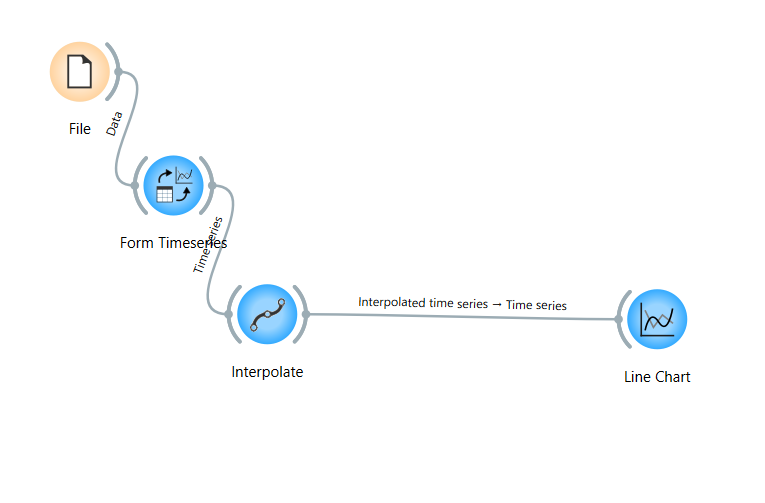

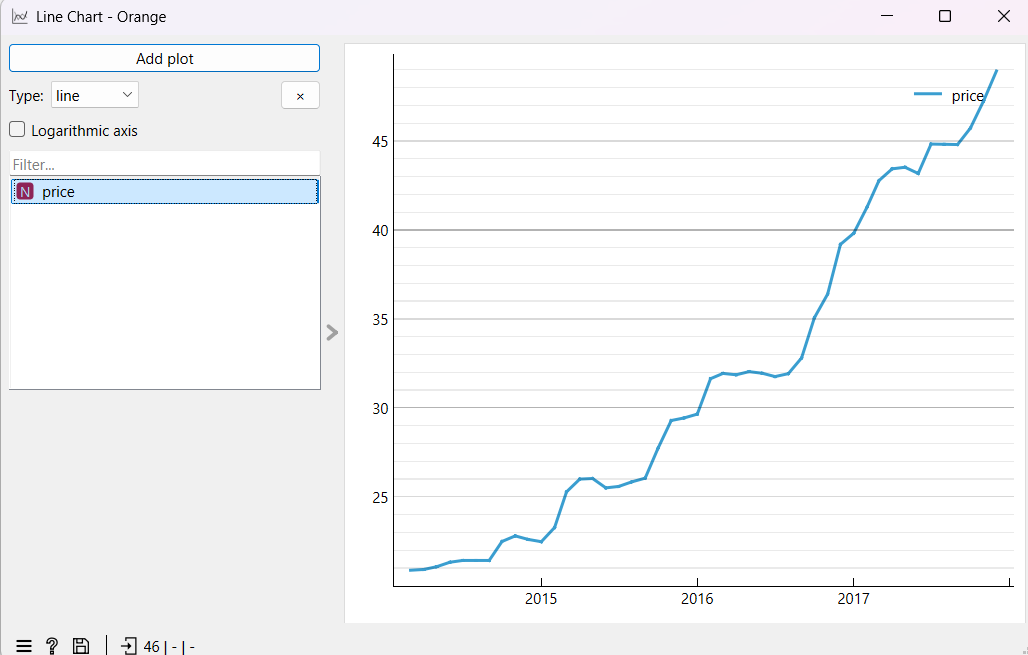

## Завдання 12. Автокореляція та диференціювання

Додайте до потоку віджети `Correlogram`, `Difference` та `Seasonal Adjustment`.

**У звіті наведіть:**
1. знімок корелограми;
2. зіставлення з ACF із завдання 5: **чи збігаються висновки** про значущі лаги;
3. знімок сезонно скоригованого ряду та порівняння з сезонною складовою STL із завдання 4.

> 💡 **Підказка.** Orange і statsmodels рахують автокореляцію однаково — якщо картина різна, перевірте, чи однакові дані на вході.

In [14]:
# Завдання 12. Автокореляція та диференціювання

**Висновок до завдання 12:**

*(напишіть тут)*

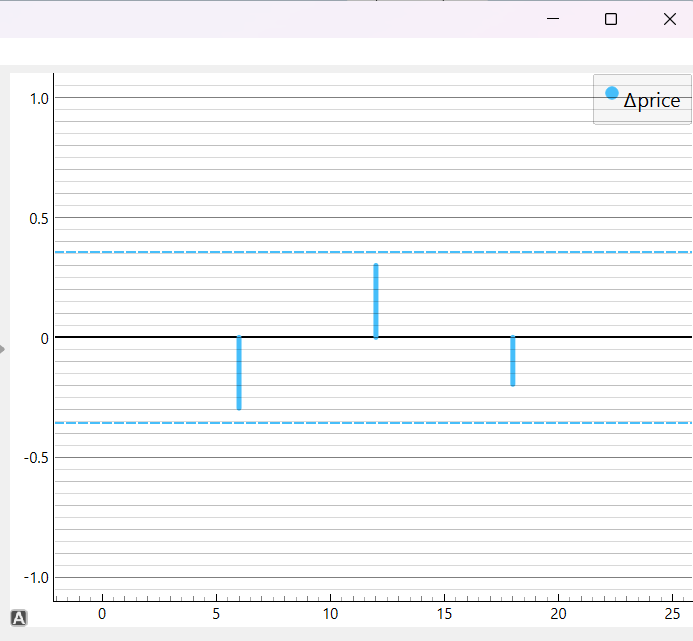

Корелолграма показує, що висновки про значущі лаги збігаються зі висновками з завдання 5 для першої різниці

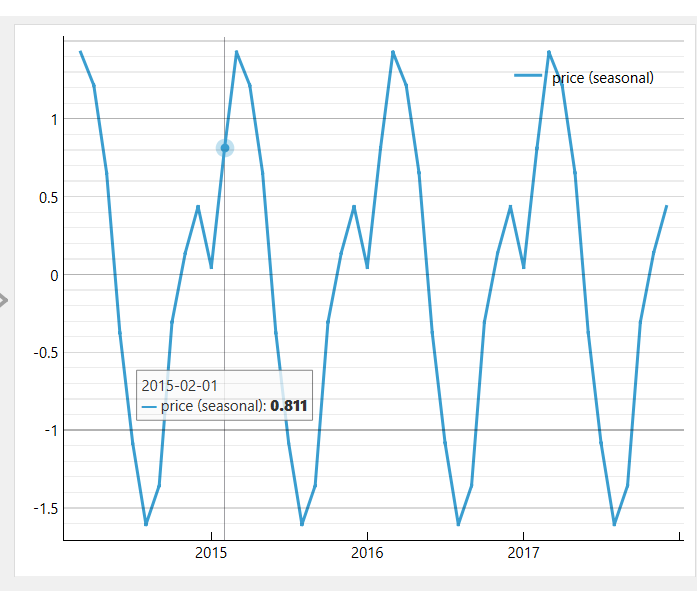

Графік сезонно скоригованого ряду збігся із графіком отриманим у 4-му завданні при застосуванні методу STL

## Завдання 13. Модель і оцінювання

Додайте `ARIMA Model` з порядком **(1, 1, 1)** та `Model Evaluation`.

У віджеті **Model Evaluation** встановіть **Number of folds = 7** та **Forecast steps = 3**.

**У звіті наведіть:**
1. знімок таблиці Model Evaluation з усіма метриками;
2. **що станеться, якщо лишити типові налаштування** (20 фолдів × 3 кроки) — наведіть повідомлення, яке видасть Orange, і поясніть, звідки воно береться;
3. які саме 7 фолдів перевіряє Orange — тобто на яких відрізках ряду навчається модель.

> 💡 **Підказка.** Orange відмовиться працювати при типових налаштуваннях. Це не збій, а наслідок довжини вашого ряду — порахуйте, якої саме.

In [15]:
# Завдання 13. Модель і оцінювання


**Висновок до завдання 13:**

*(напишіть тут)*

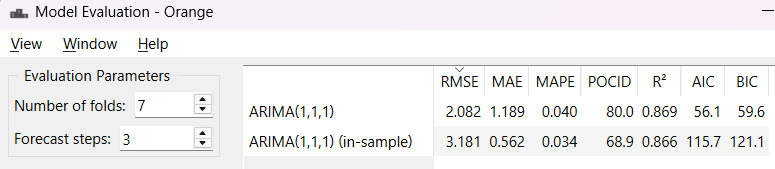

￼ Unexpected error: Supplied time series is too short for this many folds / step size. Retry with fewer iterations. - помилку одержали, оскільки у нас є дані по 46 місяцях, а 20 фолдів по 3 місяці це хоча б 60 необхідних місяців.

Orange використовує крос-валідацію - на першій ітерації він перевірятиме horizon останніх запитів, використовуючи попередні записи як навчальну вибірку, на кожній ітерації після цього вікно на horizon переміщується вліво, тобто якщо на першому фолді ми використали перших 45 записів як навчальну вибірку, то на останньому фолді ми використаємо для навчання перших 27 записів. 

## Завдання 14. Чому числа не збігаються

Порівняйте метрики Orange з метриками, які ви отримали в Частині 1 для **тієї самої** моделі
ARIMA(1,1,1) на **тих самих** 7 фолдах.

Для кожної з чотирьох метрик Orange — `RMSE`, `MAE`, `MAPE`, `POCID` — **відтворіть її значення в Python**,
тобто напишіть формулу, за якою Orange отримав саме це число, і переконайтеся, що ваш розрахунок
збігається з таблицею Orange до третього знака.

**У звіті наведіть:**
1. таблицю на чотири рядки: метрика · значення Orange · ваше відтворення в Python · формула;
2. **яка з метрик не відповідає своїй назві** — і чим саме вона відрізняється від того, що зазвичай позначають цією абревіатурою;
3. яка метрика збіглася між середовищами одразу і чому;
4. висновок: що саме треба перевіряти, перш ніж порівнювати числа з двох різних інструментів.

> 💡 **Підказка.** Жодна з розбіжностей не є помилкою Orange. Усі формули відкриті — шукайте їх у вихідному коді додатка Timeseries, файл `functions.py`.

In [21]:
def rmse(true, pred):
    true = np.asarray(true)
    pred = np.asarray(pred)
    nobs = len(pred)
    return np.sqrt(np.sum((true[-nobs:] - pred) ** 2) / nobs)

def mae(true, pred):
    true = np.asarray(true)
    pred = np.asarray(pred)
    nobs = len(pred)
    return np.median(np.abs(true[-nobs:] - pred))

def mape(true, pred):
    true = np.asarray(true)
    pred = np.asarray(pred)
    nobs = len(pred)
    return np.mean(np.abs(true[-nobs:] - pred)) / np.abs(true).mean()

def pocid(true, pred):
    true = np.asarray(true)
    pred = np.asarray(pred)
    nobs = len(pred)
    return 100 * np.mean((np.diff(true[-nobs:]) * np.diff(pred)) >= 0)

orange_results = {
    "RMSE": 2.082,
    "MAE": 1.189,
    "MAPE": 0.040,
    "POCID": 80.0
}

full_true = []
full_pred = []

for i in range(folds):
    train_end = n - test_size_total + (i * horizon)
    train = y[:train_end]
    test = y[train_end : train_end + horizon]
    
    model = ARIMA(train, order=(1, 1, 1)) 
    fitted = model.fit()
    pred = fitted.forecast(steps=horizon)
    
    full_true.extend(test)
    full_pred.extend(pred)

full_true = np.array(full_true)
full_pred = np.array(full_pred)

python_results = {
    "RMSE": rmse(full_true, full_pred),
    "MAE": mae(full_true, full_pred),
    "MAPE": mape(full_true, full_pred),
    "POCID": pocid(full_true, full_pred)
}

formulas = {
    "RMSE": "sqrt(sum((y - pred)^2) / N)",
    "MAE": "median(abs(y - pred))",
    "MAPE": "mean(abs(y - pred)) / mean(abs(y))",
    "POCID": "100 * mean(diff(y) * diff(pred) >= 0)"
}

rows = []
for metric in ["RMSE", "MAE", "MAPE", "POCID"]:
    o_val = orange_results[metric]
    p_val = python_results[metric]
    rows.append({
        "Метрика": metric,
        "Orange": f"{o_val:.3f}",
        "Python": f"{p_val:.3f}",
        "Формула": formulas[metric]
    })

results_table = pd.DataFrame(rows)
print("\n=== Завдання 14: Orange vs Python ===")
print(results_table.to_string(index=False))


=== Завдання 14: Orange vs Python ===
Метрика Orange Python                               Формула
   RMSE  2.082  2.082           sqrt(sum((y - pred)^2) / N)
    MAE  1.189  1.189                 median(abs(y - pred))
   MAPE  0.040  0.040    mean(abs(y - pred)) / mean(abs(y))
  POCID 80.000 75.000 100 * mean(diff(y) * diff(pred) >= 0)


**Висновок до завдання 14:**

*(напишіть тут)*

В Orange своїм назвам не відповідають MAE, оскільки вона рахується через медіану, та MAPE, бо це просто відношення середньої помилки до середнього значення всього ряду.

Одразу ідеально збіглася лише метрика RMSE, адже це фундаментальна формула, яку всі бібліотеки рахують однаково.

Висновок: перед порівнянням різних програм треба завжди дивитися в їхній вихідний код та перевіряти приховані налаштування. Метрика POCID не зійшлася зовсім, навіть коли формула ідентична до вихідного коду - https://github.com/biolab/orange3-timeseries/blob/master/orangecontrib/timeseries/functions.py#L46

## Завдання 15. Матриця напрямку зміни

Метрика `POCID` у Orange вимірює, чи правильно модель передбачає **напрямок** зміни ціни.
Розгорніть її в таблицю 2×2: рядки — що сталося насправді (зросла / впала),
стовпці — що передбачила модель.

**У звіті наведіть:**
1. заповнену матрицю 2×2 для вашої моделі;
2. перевірку, що частка правильних передбачень збігається зі значенням POCID із Orange;
3. висновок: чи корисна ваша модель для рішення «купувати зараз чи чекати», і чому це **інше питання**, ніж те, на яке відповідають MAE та RMSE.

> 💡 **Підказка.** Ця матриця — часоворядовий відповідник матриці похибок із класифікації.

In [22]:
# Завдання 15. Матриця напрямку зміни

diff_true = np.diff(full_true)
diff_pred = np.diff(full_pred)

dir_true = np.where(diff_true > 0, "Зросла", "Впала")
dir_pred = np.where(diff_pred > 0, "Зросла", "Впала")

matrix = pd.crosstab(
    pd.Series(dir_true, name="Факт"), 
    pd.Series(dir_pred, name="Прогноз"), 
    margins=True, margins_name="Всього"
)

if "Зросла" in matrix.columns and "Впала" in matrix.columns:
    matrix = matrix.loc[["Зросла", "Впала", "Всього"], ["Зросла", "Впала", "Всього"]]

print("=== Завдання 15. Матриця напрямку зміни (Confusion Matrix) ===")
print(matrix)

correct_predictions = matrix.loc["Зросла", "Зросла"] + matrix.loc["Впала", "Впала"]
total_predictions = matrix.loc["Всього", "Всього"]
pocid_check = (correct_predictions / total_predictions) * 100

print(f"\nПравильних передбачень: {correct_predictions} із {total_predictions}")
print(f"Розрахований POCID: {pocid_check:.1f}%")

=== Завдання 15. Матриця напрямку зміни (Confusion Matrix) ===
Прогноз  Зросла  Впала  Всього
Факт                          
Зросла       12      3      15
Впала         2      3       5
Всього       14      6      20

Правильних передбачень: 15 із 20
Розрахований POCID: 75.0%


**Висновок до завдання 15:**

*(напишіть тут)*

Модель корисна, бо у 75% випадків правильно вгадує, зросте ціна чи впаде. Це ідеально для рішення «купувати зараз чи почекати». На відміну від MAE та RMSE, які рахують абсолютну похибку в гривнях, ми передбачаємо зросте ціна чи впаде. Тому модель приноситиме бізнесу реальну вигоду за рахунок вгаданого тренду, навіть якщо вона трохи промазує в абсолютних цифрах.

---
# Загальний висновок

Напишіть 8–12 речень, які відповідають на такі питання:

1. Чи є у вашому ряді сезонність і чим ви це довели?
2. Який метод прогнозування виявився найкращим і чи перевершив він найпростіший базис?
3. Чи знайшли ви точку зміни режиму; якщо так — чи є для неї зовнішнє пояснення?
4. Чому однаково названі метрики у двох середовищах дали різні числа?
5. Чого ви не змогли встановити через те, що ряд має лише 46 спостережень?

*(напишіть тут)*

У досліджуваному ряді цін на сметану в Одесі присутня сезонність, що підтверджується розкладанням STL, де сила сезонності дорівнює 0.5068, та графіком сезонного профілю, який показує регулярне зростання цін восени. Найкращим методом прогнозування виявився найпростіший базис, а саме метод дрейфу, який показав найменшу похибку MAE 1.19. Побудована модель ARIMA 1,1,1 дала MAE 1.24, тобто вона не змогла перевершити базис із дрейфом, оскільки ряд має дуже сильний лінійний тренд із силою 0.9901, який простіша модель вловила краще. Точку зміни режиму чітко видно восени 2016 року, коли ціни різко підскочили з 32 до понад 39 гривень. Зовнішнім поясненням цього є економічна ситуація в Україні, а також сезонне подорожчання виробництва молочної продукції. Однаково названі метрики у Python та Orange дали дещо різні числа, оскільки ці два середовища використовують різні алгоритми розбиття на фолди, оптимізації параметрів та внутрішні формули для розрахунку помилок. Через те, що ряд має лише 46 спостережень, що становить менше чотирьох повних років, ми не змогли надійно підтвердити довгострокову сезонність або побудувати складніші моделі на кшталт SARIMA, бо для їх нормального навчання банально не вистачає даних.

---
# Критерії оцінювання

| Бали | Умова |
|---|---|
| **0** | Ряд не розкладено або прогноз не побудовано. Робота не зарахована. |
| **2** | Виконано лише Частину 1: ряд розкладено й прогноз побудовано, але в Orange аналіз не відтворено. |
| **3** | Виконано обидві частини, проте прогноз не зіставлено з наївним базисом, а розбіжність результатів двох середовищ не пояснено. |
| **4** | Ряд розкладено на складові; прогноз зіставлено з наївним базисом за ретроспективною перевіркою з рухомим початком; той самий аналіз відтворено в Orange; зіставлено результати двох середовищ і пояснено розбіжність метрик. |

**Знімаються бали за:**

* графіки без пояснення вибору геометрії та шкали;
* числа без письмового висновку;
* прогноз без порівняння з базисом;
* висновок «метрики різні, бо середовища різні» без відтворення формул;
* зошит, який не виконується від початку до кінця.

---
# Декларація про використання штучного інтелекту

Використання інструментів штучного інтелекту під час виконання цієї роботи **дозволено**.
Умова одна: ви маєте розуміти кожен рядок зданого коду й кожне написане твердження
і бути готовим пояснити їх на захисті.

Заповніть таблицю. Якщо ШІ не використовувався, напишіть «не використовувався» в першому рядку
й залиште решту порожньою.

| Питання | Ваша відповідь |
|---|---|
| Які інструменти використано (назва, версія) | Gemini Argon |
| Для яких саме завдань | 15, 14, 10, 8, 7, 6, 5, 4, 3|
| Що саме було згенеровано (код / текст / пояснення / виправлення помилок) | код, текст |
| Що ви змінили у згенерованому результаті й чому | помилки, неточності в коді, неправильний текст |
| Що з отриманого ви **перевірили самостійно** і яким способом | гіпотези подані ШІ, перевірив пошуком інформації вручну |
| Чи траплялися у відповідях ШІ помилки; якщо так — які | так, в більшості галюцинації, дублювання коду |

**Підтверджую, що розумію весь зданий код і всі зроблені висновки
та можу пояснити будь-яку їх частину на захисті роботи.**

Підпис: Кутельмах Є.П.  Дата: 02.11.2026